# Project 2 · Recognise licence plates using OCR (traffic-violation detection)

**Assignment:** use **video footage of vehicles at a traffic junction**, **detect vehicles violating traffic rules**, and **recognise their licence plates using OCR** (Tesseract or EasyOCR).
**Tech stack:** OpenCV, **YOLO/SSD** for object detection, Python, an OCR library.
**Deliverables checklist:**
- [ ] **demo video showing detection of violations** (Section 7 writes `output/violations_demo.mp4`)
- [ ] **accuracy report on detection** (Section 8)

The violation we detect is **jumping a red light**: a vehicle crosses the stop line while the signal is red. It's the classic junction violation, and the same structure works for others (see the ideas at the end).

> The notebook ran once in **demo mode** on a *synthetic* junction video it generates itself (cartoon cars with known plates), so every step and the accuracy numbers can be checked. For your submission, record or download real junction footage, set `VIDEO_PATH`, `DEMO = False`, `DETECTOR = "yolo"`, and adjust the stop line and traffic-light region (Section 2).

## The pipeline (put this diagram in your report)

```
video frame ─► 1. DETECT vehicles ──────► 2. TRACK them (give each vehicle an ID across frames)
                  YOLO (real footage)            │
                  or background subtraction      ▼
                  (fixed camera)          3. RULE CHECK: did this vehicle's front cross the STOP LINE
                                             while the LIGHT (read with HSV colour) was RED?
                                                 │ yes → VIOLATION
                                                 ▼
                  5. CLEAN UP the text ◄── 4. FIND the plate (contours/morphology, or a plate detector)
                     with the plate format     and READ it with OCR (EasyOCR / Tesseract)
                                                 │
                                                 ▼
                  6. LOG: time, vehicle ID, plate, snapshot  +  write the annotated demo video
```

It uses nearly everything from the course: **YOLO** (Week 3), **HSV colour detection** (Week 1 Day 1), **thresholding** (Day 4), **morphology** (Day 5), **contours and aspect ratio** (Day 6) and **tracking** (Week 1 Key Concepts).

## 0 · Setup
```
pip install opencv-python numpy pandas matplotlib ultralytics easyocr
```
The first run downloads the YOLOv8n weights (about 6 MB) and the EasyOCR models (about 100 MB).
Tesseract alternative: install the Tesseract program, then `pip install pytesseract` (see Section 4).

In [1]:
%matplotlib inline
import os, re, time, datetime
from collections import Counter
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")             # hide harmless library warnings

DEMO = True
DETECTOR = "motion"            # "motion" (fixed camera, background subtraction) or "yolo" (any footage)
VIDEO_PATH = "output/synthetic_junction.mp4" if DEMO else "data/junction.mp4"
os.makedirs("output/violations", exist_ok=True)
print("OpenCV", cv2.__version__, "| demo:", DEMO, "| detector:", DETECTOR)

OpenCV 5.0.0 | demo: True | detector: motion


## 1 · Demo footage: a synthetic junction (only when `DEMO = True`)

A fixed camera looks up a 3-lane road. The **stop line** is at y = 210 and the **signal** is in the top-right corner (green → red → green). Four cars drive through:

| Plate | What it does | Violation? |
|---|---|---|
| MH12AB3456 | crosses while green | no |
| KA05MN1234 | arrives on red, **waits**, crosses after green | no |
| DL08CA0071 | **crosses on red** | **yes** |
| TN09BZ4321 | **crosses on red** | **yes** |

Because we drew the video, we know the exact ground truth, which makes the accuracy check in Section 8 meaningful.

300 frames of 640x480 at 20 fps


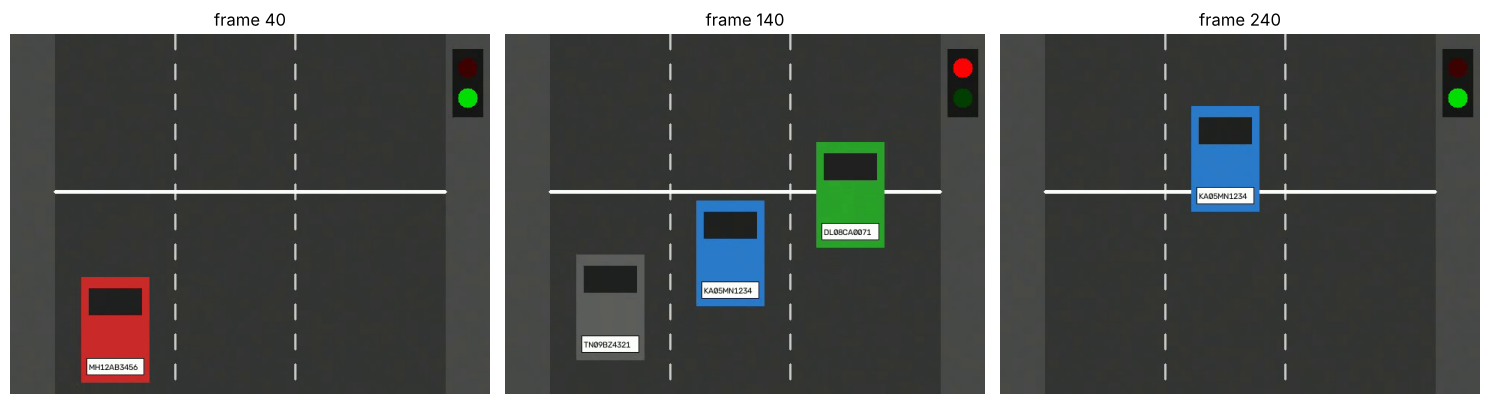

In [2]:
W, H, FPS = 640, 480, 20
STOP_Y = 210                                   # y coordinate of the stop line
LIGHT_ROI = (590, 20, 630, 110)                # x1, y1, x2, y2 of the traffic light in the frame
ROAD_X = (60, 580)                             # only look for vehicles between these x coordinates
DEMO_CARS = [("MH12AB3456", (40, 40, 200), 140, 25, "go"),
             ("KA05MN1234", (200, 120, 40), 300, 60, "stop"),
             ("DL08CA0071", (40, 160, 40), 460, 95, "run"),
             ("TN09BZ4321", (90, 90, 90), 140, 120, "run")]
GROUND_TRUTH = {"vehicles": 4, "violations": {"DL08CA0071", "TN09BZ4321"},
                "plates": {c[0] for c in DEMO_CARS}}

def demo_light(f):
    return "green" if f < 80 or f >= 220 else "red"

def make_demo_video(path, n_frames=300):
    vw = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
    ys = {i: H + 10 for i in range(len(DEMO_CARS))}
    for f in range(n_frames):
        frame = np.full((H, W, 3), (70, 70, 70), np.uint8)
        cv2.rectangle(frame, (ROAD_X[0], 0), (ROAD_X[1], H), (50, 50, 50), -1)
        for x in (220, 380):                                              # lane markings
            for y in range(0, H, 40):
                cv2.line(frame, (x, y), (x, y + 20), (200, 200, 200), 2)
        cv2.line(frame, (ROAD_X[0], STOP_Y), (ROAD_X[1], STOP_Y), (255, 255, 255), 4)
        cv2.rectangle(frame, (590, 20), (630, 110), (20, 20, 20), -1)       # signal box
        st = demo_light(f)
        cv2.circle(frame, (610, 45), 13, (0, 0, 255) if st == "red" else (0, 0, 60), -1)
        cv2.circle(frame, (610, 85), 13, (0, 220, 0) if st == "green" else (0, 60, 0), -1)
        for i, (plate, colour, x, start, behaviour) in enumerate(DEMO_CARS):
            if f < start:
                continue
            speed = 6
            front = ys[i] - 70
            if behaviour == "stop" and st == "red" and STOP_Y <= front < STOP_Y + 8 + speed:
                speed = 0                                                # waits at the line
            ys[i] -= speed
            y = ys[i]
            cv2.rectangle(frame, (x - 45, y - 70), (x + 45, y + 70), colour, -1)            # body
            cv2.rectangle(frame, (x - 35, y - 55), (x + 35, y - 20), (30, 30, 30), -1)      # windscreen
            cv2.rectangle(frame, (x - 38, y + 38), (x + 38, y + 60), (255, 255, 255), -1)   # plate
            cv2.rectangle(frame, (x - 38, y + 38), (x + 38, y + 60), (0, 0, 0), 1)
            cv2.putText(frame, plate, (x - 35, y + 54), cv2.FONT_HERSHEY_SIMPLEX, 0.36, (0, 0, 0), 1, cv2.LINE_AA)
        frame = cv2.add(frame, np.random.default_rng(f).integers(0, 8, frame.shape, dtype=np.uint8))   # sensor noise
        vw.write(frame)
    vw.release()

if DEMO:
    make_demo_video(VIDEO_PATH)
cap = cv2.VideoCapture(VIDEO_PATH)
frames = []
while True:
    ok, fr = cap.read()
    if not ok:
        break
    frames.append(fr)
cap.release()
print(f"{len(frames)} frames of {frames[0].shape[1]}x{frames[0].shape[0]} at {FPS} fps")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, f in zip(ax, [40, 140, 240]):
    a.imshow(cv2.cvtColor(frames[f], cv2.COLOR_BGR2RGB)); a.set_title(f"frame {f}"); a.axis("off")
plt.tight_layout(); plt.show()

## 2 · Configure the scene for YOUR footage
For a real video, open one frame, then read off **the stop-line y coordinate**, **the traffic-light rectangle** and **the road's x range**, and put them in `STOP_Y`, `LIGHT_ROI` and `ROAD_X` above. A quick helper to view a frame with a pixel grid:

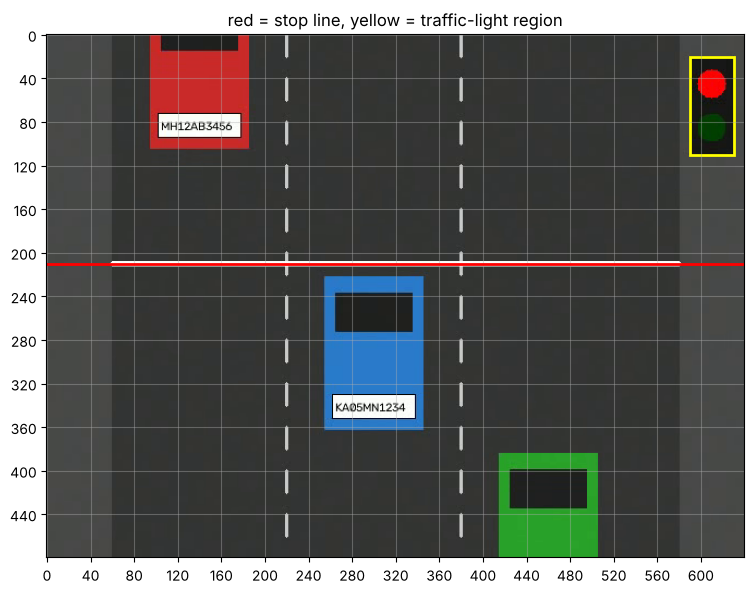

In [3]:
def show_with_grid(frame, step=40):
    plt.figure(figsize=(9, 7)); plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.xticks(range(0, frame.shape[1], step)); plt.yticks(range(0, frame.shape[0], step)); plt.grid(alpha=0.4)
    x1, y1, x2, y2 = LIGHT_ROI
    plt.gca().add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="yellow", lw=2))
    plt.axhline(STOP_Y, color="red", lw=2); plt.title("red = stop line, yellow = traffic-light region"); plt.show()

show_with_grid(frames[100])

## 3 · Step 1: detecting vehicles

### Option A: YOLO (use this for real footage)
YOLOv8 is pretrained on the COCO dataset, whose 80 classes include **car, motorcycle, bus and truck**. One forward pass gives boxes for every vehicle. Here it is on a real street photo:

YOLO found: [('bus', 0.87), ('person', 0.87), ('person', 0.85), ('person', 0.83)]


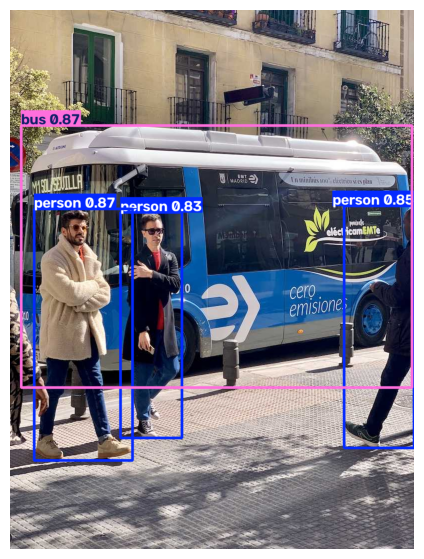

In [4]:
from ultralytics import YOLO
yolo = YOLO("yolov8n.pt")                       # 'n' = nano: smallest and fastest (downloads ~6 MB once)
VEHICLE_CLASSES = {2: "car", 3: "motorcycle", 5: "bus", 7: "truck"}

def detect_vehicles_yolo(frame, conf=0.4):
    r = yolo(frame, verbose=False, conf=conf)[0]
    boxes = []
    for (x1, y1, x2, y2), c in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist()):
        if int(c) in VEHICLE_CLASSES:
            boxes.append((int(x1), int(y1), int(x2 - x1), int(y2 - y1)))
    return boxes, r

import urllib.request
if not os.path.exists("output/street.jpg"):
    urllib.request.urlretrieve("https://github.com/ultralytics/assets/releases/download/v0.0.0/bus.jpg", "output/street.jpg")
street = cv2.imread("output/street.jpg")
boxes, result = detect_vehicles_yolo(street)
print("YOLO found:", [(yolo.names[int(c)], round(float(s), 2)) for c, s in zip(result.boxes.cls, result.boxes.conf)])
plt.figure(figsize=(6, 7)); plt.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()

### Option B: background subtraction (fixed camera, no deep learning)
A traffic camera never moves, so anything that **differs from the learned empty-road background** is a moving vehicle. OpenCV's **MOG2** learns the background over time. We then clean the foreground mask with **opening and closing** (Week 1 Day 5) and keep **big contours** (Day 6). Our cartoon cars aren't real cars, so YOLO wouldn't recognise them. The demo uses this option.

⚠️ **The catch: a vehicle that stops becomes "background".** MOG2 keeps updating its idea of the empty road. A car waiting at a red light for several seconds slowly fades into the background model, disappears from the mask, and reappears as a "new" vehicle when it drives off, already past the stop line. That breaks tracking and the crossing check exactly where we need them. (We first tried a slow learning rate of 0.001, and the waiting car still vanished after about 120 frames.)

- In the **demo** the lighting never changes, so we **freeze** the background after a short warm-up on the empty road (`LEARNING_RATE = 0`).
- **Outdoors** the light changes (clouds, evening), so the background must adapt a little (`0.0005`). Long waits can still break tracks, which is why **YOLO** is the better detector for real junctions: it recognises a car in every frame whether it moves or not.

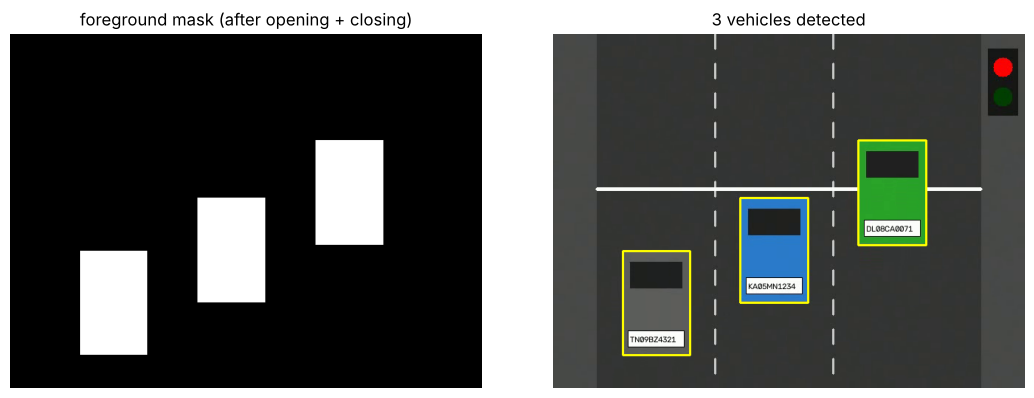

In [5]:
bg_model = cv2.createBackgroundSubtractorMOG2(history=200, varThreshold=40, detectShadows=False)
road_mask = np.zeros((H, W), np.uint8); road_mask[:, ROAD_X[0]:ROAD_X[1]] = 255

LEARNING_RATE = 0.0 if DEMO else 0.0005      # how fast the background adapts (see the note below)

def detect_vehicles_motion(frame, min_area=3000):
    fg = bg_model.apply(frame, learningRate=LEARNING_RATE)
    fg = cv2.bitwise_and(fg, road_mask)
    fg = cv2.morphologyEx(fg, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))      # remove noise specks
    fg = cv2.morphologyEx(fg, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))   # fill holes inside each car
    contours, _ = cv2.findContours(fg, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return [cv2.boundingRect(c) for c in contours if cv2.contourArea(c) > min_area], fg

for f in frames[:20]:                         # warm-up: let the model learn the empty road first
    bg_model.apply(f, learningRate=0.05)
boxes, mask = detect_vehicles_motion(frames[140])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(mask, cmap="gray"); ax[0].set_title("foreground mask (after opening + closing)")
shown = frames[140].copy()
for x, y, w, h in boxes:
    cv2.rectangle(shown, (x, y), (x + w, y + h), (0, 255, 255), 2)
ax[1].imshow(cv2.cvtColor(shown, cv2.COLOR_BGR2RGB)); ax[1].set_title(f"{len(boxes)} vehicles detected")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 4 · Steps 4–5: finding the plate and reading it

**Find the plate inside the vehicle box:** a plate is a **bright rectangle** about 2.5–6 times wider than tall. We threshold the vehicle crop (Otsu, Day 4), find contours (Day 6) and keep the largest one with a plate-like **aspect ratio** that fills its bounding box (a rectangle, not a blob).
*For real footage, a dedicated **plate detector** (YOLO trained on a plate dataset, see the end) is far more reliable than this classic method.*

**Read it with OCR:** crop just inside the border (otherwise the border gets read as "1" or "I"), **enlarge 4×**, and restrict EasyOCR to `A–Z 0–9`.

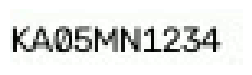

OCR read: KAOSMN1234  (confidence 0.98)


In [6]:
import easyocr
reader = easyocr.Reader(["en"], gpu=False, verbose=False)
ALLOWED = "ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"

def find_plate(vehicle_crop):
    gray = cv2.cvtColor(vehicle_crop, cv2.COLOR_BGR2GRAY)
    _, th = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    best = None
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        if 2.5 < w / max(h, 1) < 6 and w > 30 and cv2.contourArea(c) > 0.7 * w * h:
            if best is None or w * h > best[2] * best[3]:
                best = (x, y, w, h)
    return best

def read_plate(vehicle_crop):
    box = find_plate(vehicle_crop)
    if box is None:
        return None
    x, y, w, h = box
    plate = vehicle_crop[y + 2:y + h - 2, x + 2:x + w - 2]                     # just inside the border
    big = cv2.resize(plate, None, fx=4, fy=4, interpolation=cv2.INTER_CUBIC)
    result = reader.readtext(big, allowlist=ALLOWED)
    if not result:
        return None
    text, conf = max(((r[1], r[2]) for r in result), key=lambda t: t[1])
    return text, float(conf), plate

# Try it on one car from the video
boxes, _ = detect_vehicles_motion(frames[150])
x, y, w, h = max(boxes, key=lambda b: b[3])
out = read_plate(frames[150][y:y + h, x:x + w])
if out:
    text, conf, crop = out
    plt.figure(figsize=(3, 1.2)); plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()
    print(f"OCR read: {text}  (confidence {conf:.2f})")

### Step 5: fix OCR mistakes using the plate format

OCR confuses look-alike characters: **0/O/D, 1/I, 2/Z, 5/S, 8/B, 6/G**. Indian plates follow a fixed pattern:

  **2 letters (state) · 1–2 digits (district) · 1–3 letters (series) · 4 digits (number)**   e.g. **MH 12 AB 3456**

So in a *letter* position, a "0" must really be "O", and in a *digit* position an "O" must be "0". We try each way of splitting the string into those four parts and keep the one needing the fewest corrections. A two-digit district is preferred, because it's far more common.

In [7]:
TO_LETTER = {"0": "O", "1": "I", "2": "Z", "5": "S", "8": "B", "6": "G", "4": "A", "7": "T"}
TO_DIGIT = {v: k for k, v in TO_LETTER.items()}
TO_DIGIT.update({"D": "0", "Q": "0", "U": "0"})

def fix_plate(text):
    t = re.sub("[^A-Z0-9]", "", text.upper())
    best = None
    for district_len in (2, 1):
        for series_len in (2, 1, 3):
            if 2 + district_len + series_len + 4 != len(t):
                continue
            parts = [(t[:2], "L"), (t[2:2 + district_len], "D"), (t[2 + district_len:2 + district_len + series_len], "L"), (t[-4:], "D")]
            fixed, cost, possible = "", 0 if district_len == 2 else 2, True
            for chunk, kind in parts:
                for ch in chunk:
                    if kind == "L" and ch.isdigit():
                        possible &= ch in TO_LETTER; fixed += TO_LETTER.get(ch, ch); cost += 1
                    elif kind == "D" and ch.isalpha():
                        possible &= ch in TO_DIGIT; fixed += TO_DIGIT.get(ch, ch); cost += 1
                    else:
                        fixed += ch
            if possible and (best is None or cost < best[1]):
                best = (fixed, cost)
    return best[0] if best else t            # no valid split: return the cleaned text unchanged

for raw in ["MH1ZAB3456", "KAOSMN1234", "DLOBCAOO71", "TND9BZ4321", "TN09BZ4321"]:
    print(f"{raw:<12} -> {fix_plate(raw)}")

MH1ZAB3456   -> MH12AB3456
KAOSMN1234   -> KA05MN1234
DLOBCAOO71   -> DL08CA0071
TND9BZ4321   -> TN09BZ4321
TN09BZ4321   -> TN09BZ4321


**Tesseract instead of EasyOCR** (the brief allows either):
```python
import pytesseract                        # also install the Tesseract program itself
# pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"   # Windows
gray = cv2.cvtColor(big, cv2.COLOR_BGR2GRAY)
_, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
text = pytesseract.image_to_string(binary, config="--psm 7 -c tessedit_char_whitelist=" + ALLOWED)
```
`--psm 7` tells Tesseract the image is **a single line of text**. Tesseract likes clean black-on-white binary images, so threshold first (Day 4).

## 3b · Steps 2–3: tracking vehicles and checking the rule

**Tracking:** detections in each frame are just boxes. To know that *this* box is the *same* car as last frame, we match each box to the nearest existing track (a **centroid tracker**). Real systems use SORT/DeepSORT, which add a **Kalman filter** to predict where each car moves next (Week 1 Key Concepts).

**Signal state:** look at the traffic-light region in **HSV** and count bright red pixels versus bright green pixels (red needs two hue ranges because it wraps around 0/179, Week 1 Day 1).

**Rule:** a violation happens when a vehicle's **front edge** moves from below the stop line to above it **while the light is red**.

In [8]:
def light_state(frame):
    x1, y1, x2, y2 = LIGHT_ROI
    hsv = cv2.cvtColor(frame[y1:y2, x1:x2], cv2.COLOR_BGR2HSV)
    red = cv2.countNonZero(cv2.inRange(hsv, (0, 120, 150), (10, 255, 255)) | cv2.inRange(hsv, (170, 120, 150), (179, 255, 255)))
    green = cv2.countNonZero(cv2.inRange(hsv, (40, 120, 150), (90, 255, 255)))
    return "red" if red > green else "green"

print("signal at frames 40 / 140 / 240:", [light_state(frames[f]) for f in (40, 140, 240)])

class CentroidTracker:
    def __init__(self, max_distance=60, max_missing=10):
        self.tracks, self.next_id = {}, 0
        self.max_distance, self.max_missing = max_distance, max_missing

    def update(self, boxes, frame_no):
        assigned = []
        for box in sorted(boxes, key=lambda b: -b[2] * b[3]):
            x, y, w, h = box
            cx, cy = x + w / 2, y + h / 2
            candidates = [(np.hypot(cx - t["centre"][0], cy - t["centre"][1]), tid) for tid, t in self.tracks.items()
                          if tid not in [a[0] for a in assigned] and frame_no - t["last_seen"] <= self.max_missing]
            dist, tid = min(candidates) if candidates else (None, None)
            if tid is None or dist > self.max_distance:
                tid = self.next_id; self.next_id += 1
                self.tracks[tid] = {"front_history": [], "reads": [], "violation_frame": None, "crossed": False}
            t = self.tracks[tid]
            t.update(centre=(cx, cy), box=box, last_seen=frame_no)
            t["front_history"].append(y)
            assigned.append((tid, box))
        return assigned

signal at frames 40 / 140 / 240: ['green', 'red', 'green']


## 6–7 · Run the whole pipeline and write the demo video

processed 300 frames in 17.5 s -> output/violations_demo.mp4
 vehicle_id      plate  plate_reads  crossed_line  violation  violation_time_s
          0 MH12AB3456           18          True      False               NaN
          1 KA05MN1234           60          True      False               NaN
          2 DL08CA0071           18          True       True              6.50
          3 TN09BZ4321           18          True       True              7.75


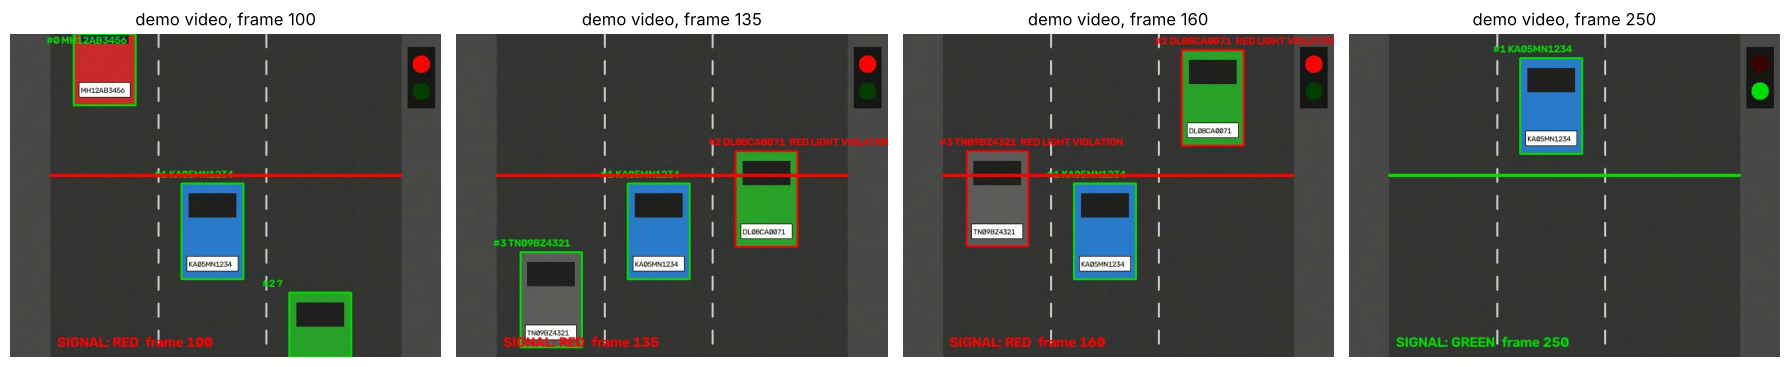

In [9]:
bg_model = cv2.createBackgroundSubtractorMOG2(history=200, varThreshold=40, detectShadows=False)
for f in frames[:20]:
    bg_model.apply(f, learningRate=0.05)                                # warm-up: learn the empty road quickly
tracker = CentroidTracker()
writer = cv2.VideoWriter("output/violations_demo.mp4", cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
violations = []
t0 = time.time()
for f, frame in enumerate(frames):
    boxes = detect_vehicles_yolo(frame)[0] if DETECTOR == "yolo" else detect_vehicles_motion(frame)[0]
    signal = light_state(frame)
    view = frame.copy()
    for tid, (x, y, w, h) in tracker.update(boxes, f):
        t = tracker.tracks[tid]
        hist = t["front_history"]
        if not t["crossed"] and len(hist) >= 2 and hist[-2] >= STOP_Y > hist[-1]:      # front just crossed the line
            t["crossed"] = True
            if signal == "red":
                t["violation_frame"] = f
                cv2.imwrite(f"output/violations/vehicle{tid}_frame{f}.jpg", frame[max(y, 0):y + h, x:x + w])
        if f % 3 == 0 and y > 0 and y + h < H - 2:                                    # read the plate every 3rd frame
            read = read_plate(frame[y:y + h, x:x + w])
            if read:
                t["reads"].append(fix_plate(read[0]))
        plate = Counter(t["reads"]).most_common(1)[0][0] if t["reads"] else "?"
        colour = (0, 0, 255) if t["violation_frame"] is not None else (0, 220, 0)
        cv2.rectangle(view, (x, y), (x + w, y + h), colour, 2)
        label = f"#{tid} {plate}" + ("  RED LIGHT VIOLATION" if t["violation_frame"] is not None else "")
        cv2.putText(view, label, (x - 40, max(15, y - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, colour, 2)
    cv2.line(view, (ROAD_X[0], STOP_Y), (ROAD_X[1], STOP_Y), (0, 0, 255) if signal == "red" else (0, 220, 0), 3)
    cv2.putText(view, f"SIGNAL: {signal.upper()}  frame {f}", (70, H - 15), cv2.FONT_HERSHEY_SIMPLEX, 0.7,
                (0, 0, 255) if signal == "red" else (0, 220, 0), 2)
    writer.write(view)
    if f in (100, 135, 160, 250):
        cv2.imwrite(f"output/frame_{f}.jpg", view)
writer.release()
print(f"processed {len(frames)} frames in {time.time() - t0:.1f} s -> output/violations_demo.mp4")

log = []
for tid, t in tracker.tracks.items():
    if len(t["front_history"]) < 5:
        continue                                                        # ignore short-lived noise tracks
    plate = Counter(t["reads"]).most_common(1)[0][0] if t["reads"] else ""
    log.append({"vehicle_id": tid, "plate": plate, "plate_reads": len(t["reads"]),
                "crossed_line": t["crossed"], "violation": t["violation_frame"] is not None,
                "violation_time_s": round(t["violation_frame"] / FPS, 2) if t["violation_frame"] is not None else None})
log = pd.DataFrame(log)
log.to_csv("output/vehicle_log.csv", index=False)
log[log.violation].to_csv("output/violations.csv", index=False)
print(log.to_string(index=False))

fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, f in zip(ax, (100, 135, 160, 250)):
    a.imshow(cv2.cvtColor(cv2.imread(f"output/frame_{f}.jpg"), cv2.COLOR_BGR2RGB)); a.axis("off"); a.set_title(f"demo video, frame {f}")
plt.tight_layout(); plt.show()

## 8 · Accuracy report on detection

Three numbers matter, so measure each one separately:
1. **Vehicle detection:** were all vehicles found and tracked as one ID each?
2. **Violation detection:** precision (flagged vehicles that really violated) and recall (real violators that got flagged).
3. **Plate recognition:** exact-match rate, plus **character accuracy** (partial credit, measured with edit distance). Report it **before and after** the format correction, to show what the post-processing adds.

For real footage, write your own ground truth by watching the video: a CSV with each vehicle's true plate and whether it violated.

In [10]:
def edit_distance(a, b):
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (ca != cb))
    return d[-1]

if DEMO:
    found = set(log.plate) & GROUND_TRUTH["plates"]
    flagged = set(log[log.violation].plate)
    tp = len(flagged & GROUND_TRUTH["violations"]); fp = len(flagged - GROUND_TRUTH["violations"]); fn = len(GROUND_TRUTH["violations"] - flagged)
    print(f"Vehicles found with a correctly read plate: {len(found)} / {GROUND_TRUTH['vehicles']}   (tracks created: {len(log)})")
    print(f"Violations: TP {tp}, FP {fp}, FN {fn}  ->  precision {tp / max(tp + fp, 1):.0%}, recall {tp / max(tp + fn, 1):.0%}")

    # OCR accuracy on every individual read of every car, before vs after the format fix
    raw_reads, truths = [], []
    for plate, colour, x, start, behaviour in DEMO_CARS:
        car = np.full((140, 90, 3), colour, np.uint8)
        cv2.rectangle(car, (7, 108), (83, 130), (255, 255, 255), -1); cv2.rectangle(car, (7, 108), (83, 130), (0, 0, 0), 1)
        cv2.putText(car, plate, (10, 124), cv2.FONT_HERSHEY_SIMPLEX, 0.36, (0, 0, 0), 1, cv2.LINE_AA)
        for k in range(5):                                     # 5 noisy views of each plate
            noisy = cv2.add(car, np.random.default_rng(k).integers(0, 25, car.shape, dtype=np.uint8))
            r = read_plate(noisy)
            raw_reads.append(r[0] if r else ""); truths.append(plate)
    rows = []
    for name, preds in [("raw OCR", raw_reads), ("after format fix", [fix_plate(p) for p in raw_reads])]:
        exact = np.mean([p == t for p, t in zip(preds, truths)])
        char_acc = 1 - sum(edit_distance(p, t) for p, t in zip(preds, truths)) / sum(len(t) for t in truths)
        rows.append({"": name, "exact plate match": f"{exact:.0%}", "character accuracy": f"{char_acc:.1%}"})
    print("\nPlate OCR on", len(truths), "plate images:")
    print(pd.DataFrame(rows).to_string(index=False))

Vehicles found with a correctly read plate: 4 / 4   (tracks created: 4)
Violations: TP 2, FP 0, FN 0  ->  precision 100%, recall 100%



Plate OCR on 20 plate images:
                 exact plate match character accuracy
         raw OCR               25%              85.0%
after format fix              100%             100.0%


## 9 · Making it work on real footage (and what to write in the report)

**Use real footage:** record a junction from a footbridge or roadside with your phone, held still, at 1080p, while plates are readable. Public traffic datasets and stock clips also work. Check the dataset's licence and blur faces if you publish the video.

**Detect plates properly:** train a small YOLO plate detector. Download a licence-plate dataset in YOLO format (e.g. from Roboflow Universe, where several Indian plate datasets exist), then:
```python
from ultralytics import YOLO
model = YOLO("yolov8n.pt")
model.train(data="plates/data.yaml", epochs=50, imgsz=640)      # ~30-60 min on a Colab GPU
plate_model = YOLO("runs/detect/train/weights/best.pt")         # use it inside each vehicle box
```
**Detect the signal robustly:** a fixed `LIGHT_ROI` plus HSV works for a fixed camera. Otherwise YOLO's COCO class *traffic light* (class 9) finds the light first.

**Report outline:**
1. Objective, the violation rule, and scene setup (camera, stop line, signal region).
2. Pipeline diagram (top of this notebook) and the role of each step: YOLO/SSD vs background subtraction, tracker, HSV signal, plate localisation, OCR + format correction.
3. Results: vehicle detection rate, violation precision/recall, and plate exact-match and character accuracy **before vs after** correction, with example frames from the demo video.
4. Limitations:
   - **Night or glare:** plates and lights become hard to read.
   - **Motion blur:** use a higher shutter speed or pick the sharpest frame.
   - **Occlusion** by other vehicles.
   - **Angled or dirty plates.**
   - **Non-standard plate fonts and formats** (BH series, two-line motorcycle plates).
   - **Tracking ID switches** in dense traffic: use DeepSORT.
5. Extensions: other rules with the same structure, such as **wrong-way driving** (track direction vs lane direction), **speeding** (distance between two lines ÷ time), **no helmet** (a person detector + helmet classifier) and **stopping on a zebra crossing** (box overlaps a zone while red).